# SymPhase tutorial 20 — two-magnon (second-order) striction and damping of magnons and phonons

Tutorial 14 used the **linear** spin–lattice term ($\partial^2E/\partial X\,\partial u$, one magnon + one phonon): it hybridises bands, but
isotropic exchange striction gives **nothing** for collinear spins. Here the next order:

* **two-magnon striction** — $J(\mathbf d_0+\delta\mathbf d)=J+\sum_\gamma G^\gamma\delta d_\gamma$ inserted into the *bilinear* magnon Hamiltonian:
  $H_3=N^{-1/2}\sum_{\mathbf k,\mathbf q,\nu}(b_{\mathbf q\nu}+b^\dagger_{-\mathbf q\nu})\,\Psi^\dagger_{\mathbf k+\mathbf q}M_\nu(\mathbf k,\mathbf q)\Psi_{\mathbf k}$ — magnon scattering by phonons and
  phonon decay into two magnons, present also for collinear magnets;
* **thermal linewidths** (Fermi's golden rule, FWHM): phonons from magnon scattering and two-magnon decay; magnons from phonon
  emission, absorption and fusion;
* **phenomenological damping**: linearised Landau–Lifshitz–Gilbert equations (Gilbert $\alpha$) + lattice friction $\eta$, solved exactly for
  the coupled magnon–phonon modes.

The vertex is checked entry by entry against the first-order change of a frozen-phonon **supercell** Hamiltonian (`tests/`).

In [1]:
# run this first (works from the repository's notebooks/ folder)
import os, sys
sys.path.insert(0, os.path.abspath(".."))      # use the local package if not pip-installed
EX = os.path.abspath("../examples")
%matplotlib inline

In [2]:
import numpy as np, spglib, math, warnings
import matplotlib.pyplot as plt
warnings.simplefilter("ignore")
from symphase.magphon import analyse_mp, MagnonPhonon, plot_mp
from symphase.magdamp import MagnonPhononVertex, gilbert_first_order, linewidths_along_path, plot_linewidths, bose
a = 3.0
lat, fr = np.diag([a, 12, 12]), np.zeros((1, 3))
ds = spglib.get_symmetry_dataset((lat, fr, [0]))
GX = [("Γ", (0, 0, 0)), ("X", (0.5, 0, 0))]
def fm_chain(dJdr=3.0, J=-5.0, K=0.3, n_per=60):
    return analyse_mp(lat, fr, [0], ["Fe"], np.array([[0, 0, 2.0]]), ds.rotations, ds.translations,
                      springs=[(0, 0, [1, 0, 0], 600.0, 300.0)], dJdr=[dJdr], J=[J], K=K, K_axis=[0, 0, 1], spin=1.0,
                      rmax=3.1, n_per=n_per, path=GX, masses=[55.845])
lat2, fr2 = np.diag([2 * a, 12, 12]), np.array([[0, 0, 0], [0.5, 0, 0]])
ds2 = spglib.get_symmetry_dataset((lat2, fr2, [0, 0]))
def afm_chain(J=4.0, K=0.15, dJdr=3.0, kL=900.0, kT=400.0, n_per=60):
    return analyse_mp(lat2, fr2, [0, 0], ["Fe", "Fe"], np.array([[0, 0, 3.0], [0, 0, -3.0]]), ds2.rotations,
                      ds2.translations, springs=[(0, 1, [0, 0, 0], kL, kT), (1, 0, [1, 0, 0], kL, kT)], dJdr=[dJdr],
                      J=[J], K=K, K_axis=[0, 0, 1], spin=1.5, rmax=3.1, n_per=n_per, path=GX, masses=[55.845, 55.845])


## 1. FM chain: no linear coupling, but finite phonon linewidths

Isotropic exchange striction $\mathrm dJ/\mathrm dr=3$ meV/Å. The linear hybridisation is exactly zero; the two-magnon process (a phonon absorbed by
scattering a thermal magnon $k\to k+q$) gives a finite width:

linear hybridisation max |ω − ω0| = 0.0 meV


T =   10 K   longitudinal phonon ω = 13.078 meV   γ = 0.00050 meV
T =   50 K   longitudinal phonon ω = 13.078 meV   γ = 0.01835 meV
T =  100 K   longitudinal phonon ω = 13.078 meV   γ = 0.04481 meV
T =  200 K   longitudinal phonon ω = 13.078 meV   γ = 0.09510 meV
T =  300 K   longitudinal phonon ω = 13.078 meV   γ = 0.14430 meV
T =  450 K   longitudinal phonon ω = 13.078 meV   γ = 0.21757 meV
T =  600 K   longitudinal phonon ω = 13.078 meV   γ = 0.29062 meV


Text(0.5, 1.0, 'scattering of thermal magnons ∝ n(ε)')

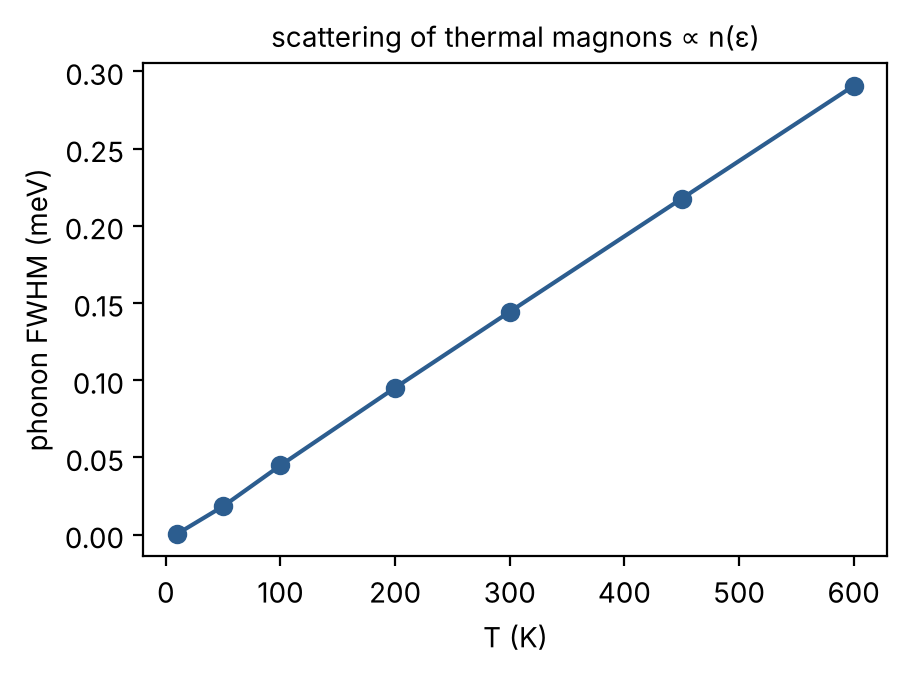

In [3]:
r = fm_chain()
vx = MagnonPhononVertex(r["model"])
print("linear hybridisation max |ω − ω0| =", np.nanmax(np.abs(r["omega"] - r["omega0"])), "meV")
q = np.array([0.9, 0, 0]); om, fs = vx.phonons(q)
nu = int(np.argmax([abs(x[0, 0]) if x is not None else 0 for x in fs]))
Ts = [10, 50, 100, 200, 300, 450, 600]
gs = [vx.phonon_linewidth(q, T=T, grid=(4000, 1, 1), sigma=0.02, modes=[nu])["gamma"][nu] for T in Ts]
for T, g in zip(Ts, gs):
    print(f"T = {T:4d} K   longitudinal phonon ω = {om[nu]:.3f} meV   γ = {g:.5f} meV")
fig, ax = plt.subplots(figsize=(4.8, 3.2)); ax.plot(Ts, gs, "o-", color="#2c5d8f")
ax.set_xlabel("T (K)"); ax.set_ylabel("phonon FWHM (meV)"); ax.set_title("scattering of thermal magnons ∝ n(ε)", fontsize=10)

**Check of the Brillouin-zone sum.** In 1D the energy δ-function can be solved: roots $k^*$ of $\varepsilon(k+q)-\varepsilon(k)=\omega$,
$\gamma = a\sum_{k^*}|S(k^*)|^2\,[n(\varepsilon_{k^*})-n(\varepsilon_{k^*+q})]/|\partial_k(\varepsilon_{k+q}-\varepsilon_k)|$:

In [4]:
S_, J_, K_ = 1.0, 5.0, 0.3
eps = lambda k: 2 * S_ * J_ * (1 - np.cos(k * a)) + 2 * K_ * S_
s = om[nu] / (4 * S_ * J_ * np.sin(q[0] * a / 2)); ref = 0.0
for base in (math.asin(s), math.pi - math.asin(s)):
    k = (base - q[0] * a / 2) / a
    Sm = vx.scattering(np.array([k, 0, 0]), q, fs[nu])[0, 0]
    ref += a * abs(Sm) ** 2 * (bose(eps(k), 300) - bose(eps(k + q[0]), 300)) / (4 * S_ * J_ * a * np.sin(q[0] * a / 2) * abs(math.cos(k * a + q[0] * a / 2)))
print(f"semi-analytic γ = {ref:.5f} meV   BZ sum = {gs[Ts.index(300)]:.5f} meV")

semi-analytic γ = 0.14430 meV   BZ sum = 0.14430 meV


## 2. Magnon linewidths: phonon emission, absorption, fusion — along Γ–X

T =     0 K: magnon at X ε = 20.60 meV  γ = 0.242 (emission 0.242, absorption 0.000, fusion 0.000) meV


T =   300 K: magnon at X ε = 20.60 meV  γ = 1.972 (emission 1.625, absorption 0.347, fusion 0.000) meV


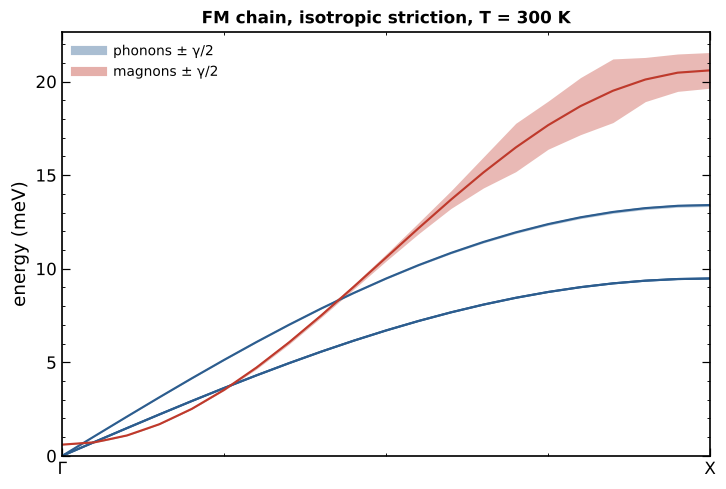

In [5]:
X = np.array([np.pi / a, 0, 0])
for T in (0.0, 300.0):
    m = vx.magnon_linewidth(X, T=T, grid=(400, 1, 1), sigma=0.2)
    print(f"T = {T:5.0f} K: magnon at X ε = {m['epsilon'][0]:.2f} meV  γ = {m['gamma'][0]:.3f} "
          f"(emission {m['gamma_emit'][0]:.3f}, absorption {m['gamma_abs'][0]:.3f}, fusion {m['gamma_fusion'][0]:.3f}) meV")
lw = linewidths_along_path(r["model"], r["q"], r["x"], T=300.0, grid=(300, 1, 1), sigma=0.2, every=3)
plot_linewidths(lw, r, title="FM chain, isotropic striction, T = 300 K");

Magnons above the top of the phonon band can **emit** phonons (spontaneously, even at $T=0$): their width grows sharply.

## 3. AFM chain: a phonon decays into two magnons — even at $T = 0$

Bogoliubov pairing in the antiferromagnet produces $\alpha^\dagger\alpha^\dagger b$ terms: an optical phonon above twice the magnon gap
decays spontaneously.

In [6]:
ra = afm_chain(); va = MagnonPhononVertex(ra["model"])
print("magnon gap:", np.round(va.magnon(np.zeros(3))[0], 3), "meV")
for qx in (0.3, 0.6, 0.9):
    qq = np.array([qx, 0, 0]); p = va.phonon_linewidth(qq, T=0.0, grid=(2000, 1, 1), sigma=0.05)
    print(f"q = {qx}:  ω = {np.round(p['omega'], 2)}\n          γ_pair(T=0) = {np.round(p['gamma_pair'], 4)}")

magnon gap: [3.317 3.317] meV


q = 0.3:  ω = [ 4.76  4.76  7.14  9.85  9.85 14.78]
          γ_pair(T=0) = [0.     0.     0.     0.     0.     0.0177]


q = 0.6:  ω = [ 6.8   6.8   8.57  8.57 10.2  12.86]
          γ_pair(T=0) = [0. 0. 0. 0. 0. 0.]


q = 0.9:  ω = [ 2.4   2.4   3.6  10.68 10.68 16.02]
          γ_pair(T=0) = [0.     0.     0.     0.     0.     0.0297]


## 4. Gilbert damping and lattice friction (linearised LLG, exact)

Ferromagnet: $\omega\to\omega/(1+\alpha^2)$, FWHM $\gamma=2\alpha\omega/(1+\alpha^2)$. Antiferromagnet: the width is **exchange-enhanced** and nearly
$k$-independent, $\gamma\approx2\alpha(2J+2K)S$ — far above $2\alpha\omega$ at small $\omega$:

In [7]:
o, g, wm = MagnonPhononVertex(r["model"]).damped_modes(np.array([0.7, 0, 0]), alpha=0.05, coupling=False)
im = int(np.argmax(wm)); e0 = 2 * 5.0 * (1 - np.cos(0.7 * a)) + 0.6
print(f"FM: ω = {o[im]:.4f} (ε/(1+α²) = {e0/(1+0.05**2):.4f}),  γ = {g[im]:.4f} (2αε/(1+α²) = {2*0.05*e0/(1+0.05**2):.4f}) meV")
for kx in (0.0, 0.4, 0.9):
    o, g, wm = va.damped_modes(np.array([kx, 0, 0]), alpha=1e-3, coupling=False)
    mg = [(x, y) for x, y, w in zip(o, g, wm) if w > 0.5]
    print(f"AFM k = {kx}: ω = {mg[0][0]:.3f} meV, γ = {mg[0][1]:.5f} meV  (2αω = {2e-3*mg[0][0]:.5f};  2α(2J+2K)S = {2e-3*(8+0.3)*1.5:.5f})")
o, g, wm = va.damped_modes(np.array([0.5, 0, 0]), alpha=0.0, eta=0.3, coupling=False)
print("pure lattice friction η = 0.3 meV -> phonon FWHM:", np.round([y for y, w in zip(g, wm) if w < 0.5], 4))

FM: ω = 15.6094 (ε/(1+α²) = 15.6094),  γ = 1.5609 (2αε/(1+α²) = 1.5609) meV
AFM k = 0.0: ω = 3.317 meV, γ = 0.02490 meV  (2αω = 0.00663;  2α(2J+2K)S = 0.02490)
AFM k = 0.4: ω = 11.666 meV, γ = 0.02490 meV  (2αω = 0.02333;  2α(2J+2K)S = 0.02490)
AFM k = 0.9: ω = 6.108 meV, γ = 0.02490 meV  (2αω = 0.01222;  2α(2J+2K)S = 0.02490)
pure lattice friction η = 0.3 meV -> phonon FWHM: [0.3 0.3 0.3 0.3 0.3 0.3]


## 5. Command line
```bash
cd examples/vasp/MagnonPhonon_FM_chain
symphase magnons --J -5 --K 0.3 --K-axis 0 0 1 --spin 1 --rmax 3.1 --phonons springs.dat --dJdr 3 \
                 --linewidth 300 --lw-grid 300 --lw-sigma 0.2 --alpha 0.01 --phonon-damping 0.05
```
writes `*_linewidths.png/.dat` (ω ± γ/2 for phonons and magnons) and prints the Gilbert/friction widths of the coupled modes.
Continue with **21_quiz_two_magnon_damping.ipynb**.